# AVIPE full hardware test: mic → FFT on the FPGA → notebook

This notebook checks the whole FPGA signal chain on hardware, with Katie's FFT in it:

```
SPH0645 → i2s_receiver → sum_of_3 → dc_removal → ring_buffer → fft (Katie) → UART → PC
```

`mic_fft_test_top` runs on the UPduino. Each time the ring buffer has a new frame and
the serial link is free, `fft_frame_uart` loads the 512 samples into the FFT, runs it,
and sends the input frame and the 512 FFT outputs to the PC in one packet (about one
frame in three, about 16 a second). The FFT halves its values after every stage
(`STAGE_SHIFT = 1`), so full 16-bit samples can't overflow and the output is about `FFT(x) / 512`.

Because each packet carries its own input, the notebook can check the hardware FFT
exactly: `fft_fixed.py` is a bit-exact Python model of the RTL, and every output word
should match it. Then it compares the hardware FFT with numpy's floating-point FFT,
and runs the MCU's next step (Hamming window, magnitude, peak bin) on the hardware output.

**Recording** (Windows, from `fpga/model`, after programming the board):

```
py ftdi_reset.py
py fft_capture.py record --seconds 3 --out captures/fft_NAME.bin
```

Recorded while the VG27B monitor speaker played: nothing (`fft_quiet`), a 1234 Hz tone
(`fft_t1234`), 500 Hz + 2.5 kHz (`fft_twotone`), and a 100 Hz → 7 kHz sweep over 6 s (`fft_sweep`).

In [1]:
# ======================= INPUTS =======================
CAPTURES = {             # capture name: tones played (Hz)
    'fft_quiet':   [],
    'fft_t1234':   [1234],
    'fft_twotone': [500, 2500],
    'fft_sweep':   None,  # sweep, checked separately
}
FS = 15669.7             # real sample rate, measured with a 1 kHz tone in hw_fft.ipynb
N  = 512

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from fft_capture import parse, check
from fft_fixed import fft_fixed

plt.rcParams.update({'figure.figsize': (11, 3.6), 'axes.grid': True, 'grid.alpha': 0.3,
                     'axes.spines.top': False, 'axes.spines.right': False, 'font.size': 10})
BIN_HZ = FS / N
freqs = np.arange(N // 2 + 1) * BIN_HZ

packets, rows = {}, []
for name in CAPTURES:
    data = open(f'captures/{name}.bin', 'rb').read()
    info = json.load(open(f'captures/{name}.json'))
    packets[name], st = parse(data)
    rows.append((name, info['seconds'], len(data), st['packets'], st['bad_checksums'], st['frame_number_gaps']))
display(pd.DataFrame(rows, columns=['capture', 'seconds', 'bytes', 'packets', 'bad checksums', 'frame number gaps']))

,capture,seconds,bytes,packets,bad checksums,frame number gaps
0,fft_quiet,3.0,156719,48,0,2
1,fft_t1234,3.0,159846,49,0,2
2,fft_twotone,3.0,159847,49,0,2
3,fft_sweep,6.5,341625,105,0,4


**Packets.** About 16 packets a second is expected: a packet is 3,080 bytes, about 41 ms at
744 kbaud, and the FPGA skips frames while one is going out. A bad checksum would mean
a byte was lost on the serial link.

## 1. Is the hardware FFT bit-exact?

Run every received input frame through `fft_fixed.py` and compare all 512 complex
outputs word for word with what the FPGA sent.

In [3]:
rows = []
for name, pk in packets.items():
    res = check(pk)
    wrong = sum(r['wrong_words'] for r in res)
    rows.append((name, len(pk), len(pk) * N, wrong))
t = pd.DataFrame(rows, columns=['capture', 'frames', 'output words checked', 'words that differ'])
display(t)
print('PASS: the FPGA FFT matches the bit-exact model on every word' if t['words that differ'].sum() == 0
      else 'FAIL: some outputs differ from the model')

,capture,frames,output words checked,words that differ
0,fft_quiet,48,24576,0
1,fft_t1234,49,25088,0
2,fft_twotone,49,25088,0
3,fft_sweep,105,53760,0


PASS: the FPGA FFT matches the bit-exact model on every word


## 2. How close is it to a perfect FFT?

SQNR compares the hardware output with numpy's floating-point FFT of the same input,
divided by 512 (the 9 halvings). Rounding the twiddles to 16 bits and halving after
every stage loses some precision, and quiet frames lose more, since their samples use
fewer bits.

In [4]:
def hw_complex(p):
    return p['re'] + 1j * p['im']

rows = []
for name, pk in packets.items():
    sq, rms = [], []
    for p in pk:
        X = np.fft.fft(p['x']) / N
        err = hw_complex(p) - X
        sq.append(10 * np.log10(np.sum(abs(X) ** 2) / np.sum(abs(err) ** 2)))
        rms.append(p['x'].std())
    rows.append((name, round(np.mean(rms)), round(np.min(sq), 1), round(np.median(sq), 1), round(np.max(sq), 1)))
display(pd.DataFrame(rows, columns=['capture', 'input rms (LSB)', 'SQNR min (dB)', 'SQNR median (dB)', 'SQNR max (dB)']))

,capture,input rms (LSB),SQNR min (dB),SQNR median (dB),SQNR max (dB)
0,fft_quiet,119,12.6,13.8,19.7
1,fft_t1234,21221,28.5,58.8,60.2
2,fft_twotone,3153,41.8,42.5,43.0
3,fft_sweep,2993,13.1,33.2,60.7


## 3. Spectra: hardware FFT vs numpy

One frame from each capture. Left: the 512 input samples the FPGA sent. Right: the
FPGA's FFT magnitude (black) and numpy's (orange, dashed) in dB, with the played tones
in red. If the hardware is right, the two curves sit on top of each other wherever
the signal is above the hardware's noise floor.

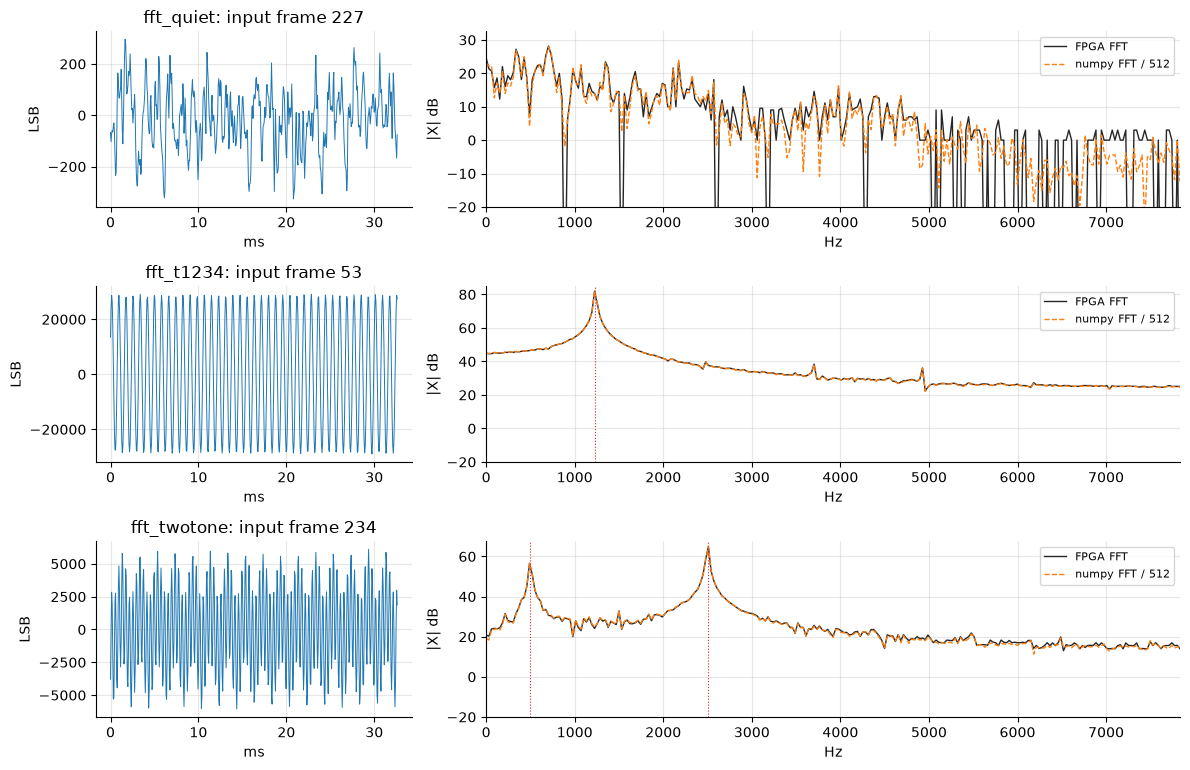

In [5]:
def db(v):
    return 20 * np.log10(np.maximum(abs(v), 1e-3))

names = [n for n in CAPTURES if n != 'fft_sweep']
fig, ax = plt.subplots(len(names), 2, figsize=(12, 2.6 * len(names)), gridspec_kw={'width_ratios': [1, 2.2]})
for row, name in zip(ax, names):
    p = packets[name][len(packets[name]) // 2]
    X = np.fft.fft(p['x']) / N
    row[0].plot(np.arange(N) / FS * 1e3, p['x'], lw=0.7)
    row[0].set(xlabel='ms', ylabel='LSB', title=f'{name}: input frame {p["frame"]}')
    row[1].plot(freqs, db(hw_complex(p)[:N // 2 + 1]), color='0.15', lw=1, label='FPGA FFT')
    row[1].plot(freqs, db(X[:N // 2 + 1]), color='tab:orange', lw=1, ls='--', label='numpy FFT / 512')
    for hz in CAPTURES[name] or []:
        row[1].axvline(hz, color='tab:red', lw=0.8, ls=':')
    row[1].set(xlabel='Hz', ylabel='|X| dB', xlim=(0, FS / 2), ylim=(-20, None))
    row[1].legend(loc='upper right', fontsize=8)
plt.tight_layout(); plt.show()

## 4. The MCU step: Hamming window and peak bin

The MCU will apply the Hamming window in the frequency domain,
`Xw[k] = 0.54 X[k] − 0.23 (X[k−1] + X[k+1])`, take the magnitude of bins 1 to 254,
and draw them as bars. This does that on the hardware outputs and finds the loudest
bin in each frame from bin 3 up (bins 0 to 2 are the fan hum), the same way
`hw_fft.ipynb` did on raw samples.

,capture,played (Hz),expected bin,bin center (Hz),frames whose loudest bar is that bin ±1
0,fft_t1234,1234,40,1224.2,49/49
1,fft_twotone,500,16,489.7,0/49
2,fft_twotone,2500,82,2509.6,49/49


(for two tones, only the louder one can be the loudest bar in a frame)


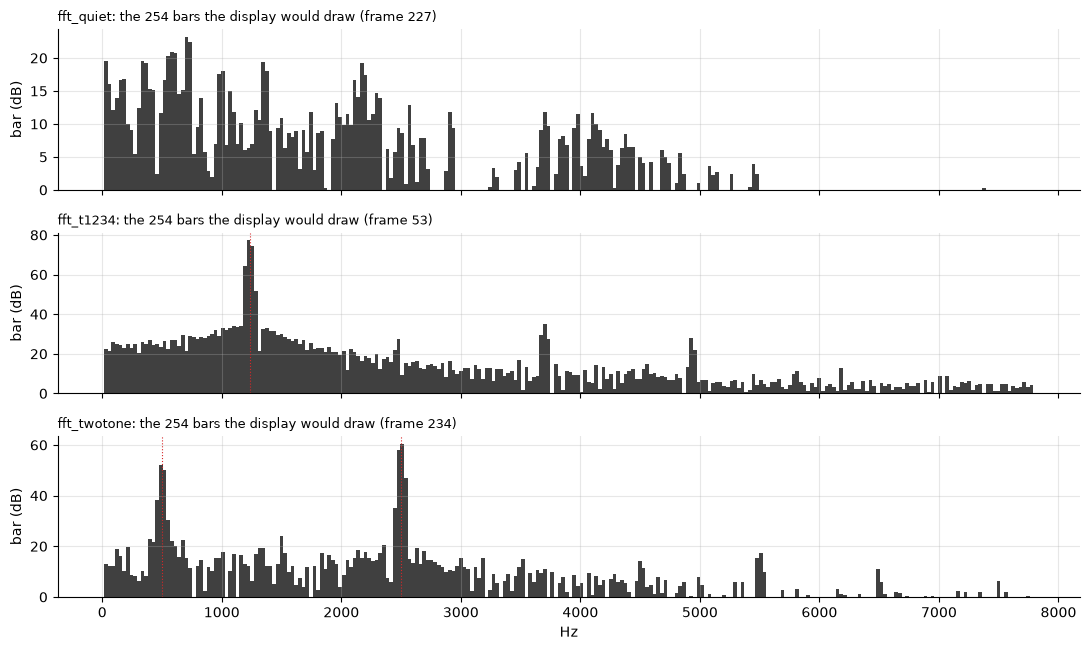

In [6]:
def mcu_bars(p):
    X = hw_complex(p)
    k = np.arange(1, 255)
    return k, abs(0.54 * X[k] - 0.23 * (X[k - 1] + X[k + 1]))

rows = []
for name, tones in CAPTURES.items():
    if not tones:
        continue
    peaks = np.array([mcu_bars(p)[0][np.argmax(mcu_bars(p)[1][2:]) + 2] for p in packets[name]])
    for hz in tones:
        kk = int(round(hz / BIN_HZ))
        near = np.abs(peaks - kk) <= 1
        rows.append((name, hz, kk, round(kk * BIN_HZ, 1), f'{near.sum()}/{len(peaks)}'))
display(pd.DataFrame(rows, columns=['capture', 'played (Hz)', 'expected bin', 'bin center (Hz)', 'frames whose loudest bar is that bin ±1']))
print('(for two tones, only the louder one can be the loudest bar in a frame)')

fig, ax = plt.subplots(len(names), 1, figsize=(11, 2.2 * len(names)), sharex=True)
for a, name in zip(ax, names):
    p = packets[name][len(packets[name]) // 2]
    k, mag = mcu_bars(p)
    a.bar(k * BIN_HZ, 20 * np.log10(np.maximum(mag, 1)), width=BIN_HZ, color='0.25')
    for hz in CAPTURES[name] or []:
        a.axvline(hz, color='tab:red', lw=0.8, ls=':')
    a.set(ylabel='bar (dB)', title=f'{name}: the 254 bars the display would draw (frame {p["frame"]})')
    a.title.set(fontsize=9); a.title.set_ha('left'); a.title.set_x(0)
ax[-1].set_xlabel('Hz')
plt.tight_layout(); plt.show()

## 5. Sweep through the hardware FFT

Every packet of the sweep capture, one column each (about 16 a second). The played sweep
goes from 100 Hz to 7 kHz on a log scale over 6 s, so the bright line should climb
steadily (a straight line on the log plot). Right: the loudest MCU bar in each frame.

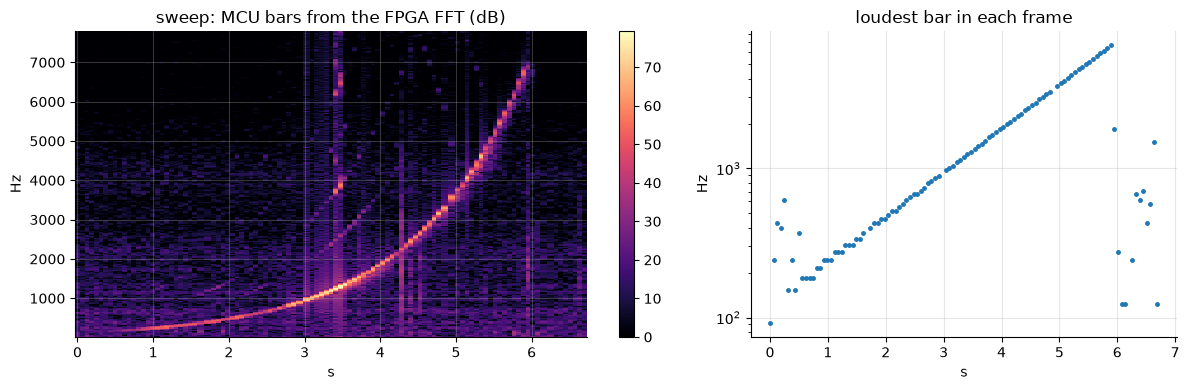

In [7]:
pk = packets['fft_sweep']
S = np.array([20 * np.log10(np.maximum(mcu_bars(p)[1], 1)) for p in pk])
raw = open('captures/fft_sweep.bin', 'rb').read()
secs = json.load(open('captures/fft_sweep.json'))['elapsed']
t = np.array([p['offset'] for p in pk]) / len(raw) * secs   # byte position -> time in the recording
k = np.arange(1, 255)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1.5, 1]})
im = ax[0].pcolormesh(t, k * BIN_HZ, S.T, shading='nearest', cmap='magma', vmin=0, vmax=S.max())
ax[0].set(xlabel='s', ylabel='Hz', title='sweep: MCU bars from the FPGA FFT (dB)')
fig.colorbar(im, ax=ax[0])
peak = k[np.argmax(S[:, 2:], axis=1) + 2] * BIN_HZ
ax[1].semilogy(t, peak, '.', ms=5)
ax[1].set(xlabel='s', ylabel='Hz', title='loudest bar in each frame')
plt.tight_layout(); plt.show()

## 6. Live FFT over USB (`mic_fft_spi_top`)

With `mic_fft_spi_top` programmed, the FPGA sends every FFT frame on the SPI pins (J3: SCK P46, MOSI P45, CS P3) **and** the same frame over the UPduino's USB serial port, so this section reads it through the USB cable. Each frame is `A55A`, `{frame number, STAGE_SHIFT}`, then re/im of X[0..255], then a checksum word (`fft_live.py`, `bins_uart.sv`).

Before running:
- `pip install pyserial numpy matplotlib`
- after programming with openFPGALoader, **unplug and replug the USB cable** (or run `ftdi_reset.py` on Windows) so the FT232H is back in serial mode
- close any other program that has the serial port open

`PORT = None` finds the UPduino; otherwise set it, e.g. `'COM5'`, `'/dev/ttyUSB0'` or `'/dev/cu.usbserial-...'`.

In [ ]:
import time
from IPython.display import clear_output
import fft_live

PORT = None          # None = find the UPduino's FTDI port
SECONDS = 20         # how long to run the live plot
FS_LIVE = fft_live.FS
freqs_live = np.arange(fft_live.BINS) * FS_LIVE / 512

ser = fft_live.open_port(PORT)
print('reading', ser.port)
hold = np.full(fft_live.BINS, -100.0)
t0, n, last = time.time(), 0, 0.0
try:
    for f in fft_live.frames_from(ser):
        db = fft_live.magnitude_db(f)
        hold = np.maximum(db, hold - 0.5)
        n += 1
        if time.time() - last > 0.2 and ser.in_waiting < 2060:     # redraw about 5 times a second
            last = time.time()
            clear_output(wait=True)
            fig, ax = plt.subplots(figsize=(10, 4.5))
            ax.plot(freqs_live, db, lw=1, label='this frame')
            ax.plot(freqs_live, hold, lw=0.8, alpha=0.5, label='peak hold')
            k = int(np.argmax(db[1:])) + 1
            ax.set_title(f'frame {f["frame"]}: peak {k * FS_LIVE / 512:.0f} Hz (bin {k}), {n / (time.time() - t0):.1f} frames/s')
            ax.set_xlim(0, FS_LIVE / 2); ax.set_ylim(-100, 0)
            ax.set_xlabel('frequency (Hz)'); ax.set_ylabel('|X[k]| (dB, 0 = full-scale sine)')
            ax.grid(alpha=0.3); ax.legend(loc='upper right')
            plt.show()
        if time.time() - t0 > SECONDS:
            break
finally:
    ser.close()
print(f'{n} frames in {time.time() - t0:.1f} s')

### Record a few seconds and look at them

Records raw USB bytes to `captures/spi_NAME.bin`, then plots a spectrogram of every frame. The recordings can be re-plotted later without the board.

In [ ]:
NAME = 'live'
REC_SECONDS = 4

out = f'captures/spi_{NAME}.bin'
fft_live.record(PORT, REC_SECONDS, out)
rec, _, bad = fft_live.parse(open(out, 'rb').read())
nums = [f['frame'] for f in rec]
gaps = sum((b - a) % 256 != 1 for a, b in zip(nums, nums[1:]))
print(f'{len(rec)} frames, {bad} bad checksums, {gaps} frame-number gaps')

S = np.array([fft_live.magnitude_db(f) for f in rec])
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(S.T, origin='lower', aspect='auto', vmin=-90, vmax=-10, cmap='magma',
               extent=[0, len(rec) * 312 / FS_LIVE, 0, FS_LIVE / 2])
ax.set_xlabel('time (s)'); ax.set_ylabel('frequency (Hz)')
ax.set_title(f'{out}: FPGA FFT read over USB')
fig.colorbar(im, label='dB')
plt.show()